# Emometer: SAE feature vs. EmoLex on the same story

Puts the two arcs on one graph: the SAE feature from `test.ipynb` (Figure 1) and the EmoLex score from `emolex-test.ipynb` (Figure 2). Each notebook saves its arc to `arcs/` when its figure cell runs, so **run those two first**; this notebook only reads the saved arcs and checks that they cover the same story with the same windows.

Each arc is min-max normalized on its own, as in Figure 3: (value − min) / (max − min), so each one's lowest window is 0 and its highest is 1. This compares the arcs' *shapes*, not their sizes: an SAE peak of 0.025 and an EmoLex peak of 0.059 both become 1. The graph is saved to `figures/figure4.png`, and the cell also prints how closely the two arcs agree.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt

SAE_ARC = Path("arcs/sae_arc.json")         # written by test.ipynb
EMOLEX_ARC = Path("arcs/emolex_arc.json")   # written by emolex-test.ipynb
CREATED_WITH = "Neuronpedia, NRC EmoLex and Claude Code"
FIG_DATE = "Nov 13, 2026"
FIG_PATH = Path("figures/figure4.png")

# Two series: the first two categorical slots (blue, orange), which pass the colour-blindness checks as a pair.
# Text and axes stay neutral.
SAE_COLOR, EMOLEX_COLOR = "#2a78d6", "#eb6834"
INK, MUTED, RULE = "#0b0b0b", "#52514e", "#e4e3df"


def normalize(values: list[float]) -> list[float]:
    """Min-max scale to [0, 1]: the lowest value becomes 0 and the highest 1."""
    lo, hi = min(values), max(values)
    return [(v - lo) / (hi - lo) if hi > lo else 0.0 for v in values]


def pearson(a: list[float], b: list[float]) -> float:
    ma, mb = sum(a) / len(a), sum(b) / len(b)
    cov = sum((x - ma) * (y - mb) for x, y in zip(a, b))
    var = (sum((x - ma) ** 2 for x in a) * sum((y - mb) ** 2 for y in b)) ** 0.5
    return cov / var if var else float("nan")


def ranks(values: list[float]) -> list[float]:
    """Average ranks (ties share the mean of their positions), for Spearman's correlation."""
    order = sorted(range(len(values)), key=values.__getitem__)
    out = [0.0] * len(values)
    i = 0
    while i < len(order):
        j = i
        while j + 1 < len(order) and values[order[j + 1]] == values[order[i]]:
            j += 1
        for k in range(i, j + 1):
            out[order[k]] = (i + j) / 2
        i = j + 1
    return out

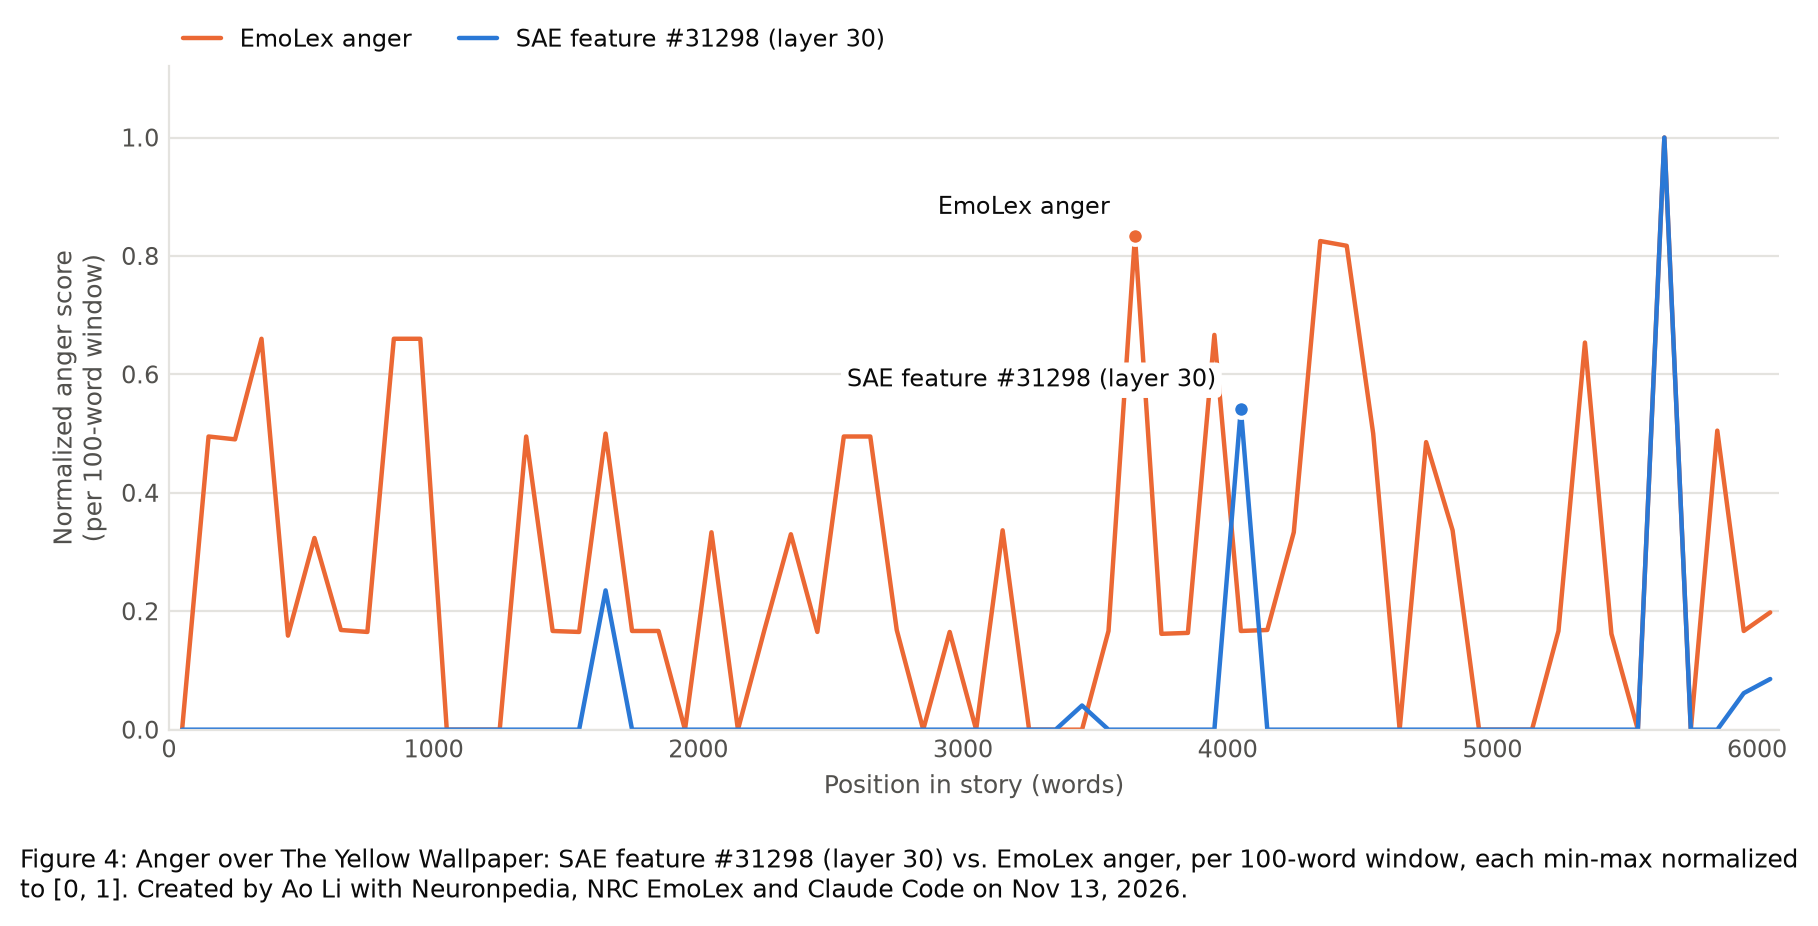

61 windows of 100 words; SAE nonzero in 6, EmoLex in 44, both in 5
Pearson r = 0.30, Spearman rho = 0.11
Peak windows (words): SAE 5600 EmoLex 5600


In [2]:
sae, emolex = json.loads(SAE_ARC.read_text()), json.loads(EMOLEX_ARC.read_text())
for key in ("story", "emotion", "window_words", "n_words", "mids"):
    if sae[key] != emolex[key]:
        raise ValueError(f"the arcs don't match on {key!r}: {sae[key]!r} vs {emolex[key]!r}; re-run both notebooks on the same settings")

mids, n_words, window = sae["mids"], sae["n_words"], sae["window_words"]
sae_norm, emolex_norm = normalize(sae["values"]), normalize(emolex["values"])

fig, ax = plt.subplots(figsize=(9, 4.2), dpi=200)
series = [(emolex["label"], emolex_norm, EMOLEX_COLOR), (sae["label"], sae_norm, SAE_COLOR)]
for label, values, color in series:
    ax.plot(mids, values, color=color, linewidth=1.6, solid_joinstyle="round", solid_capstyle="round", label=label)

# Direct labels: put each series' name where it stands furthest above the other, so the two never collide.
for (label, values, color), (_, other, _) in zip(series, series[::-1]):
    w = max(range(len(values)), key=lambda i: values[i] - other[i])
    ax.plot(mids[w], values[w], "o", markersize=6, color=color, markeredgecolor="white", markeredgewidth=1.5, zorder=3)
    right_half = mids[w] > n_words / 2
    ax.annotate(
        label, (mids[w], values[w]), xytext=(-9 if right_half else 9, 6), textcoords="offset points",
        ha="right" if right_half else "left", va="bottom", fontsize=8.5, color=INK, zorder=4,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none"),  # lines pass behind, not through
    )

ax.set_xlim(0, n_words)
ax.set_ylim(0, 1.12)
ax.set_xlabel("Position in story (words)", color=MUTED, fontsize=9)
ax.set_ylabel(f"Normalized {sae['emotion']} score\n(per {window}-word window)", color=MUTED, fontsize=9)
ax.grid(axis="y", color=RULE, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(RULE)
ax.tick_params(colors=MUTED, labelsize=8.5, length=0)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=8.5, labelcolor=INK,
          handlelength=1.6, borderaxespad=0.2)

caption = (
    f"Figure 4: {sae['emotion'].capitalize()} over {sae['story']}: {sae['label']} vs. {emolex['label']}, "
    f"per {window}-word window, each min-max normalized to [0, 1]. "
    f"Created by Ao Li with {CREATED_WITH} on {FIG_DATE}."
)
fig.text(0.0, -0.02, caption, ha="left", va="top", fontsize=9, color=INK, wrap=True)
fig.tight_layout()

FIG_PATH.parent.mkdir(exist_ok=True)
fig.savefig(FIG_PATH, bbox_inches="tight", facecolor="white")
plt.show()

both = sum(a > 0 and b > 0 for a, b in zip(sae_norm, emolex_norm))
print(f"{len(mids)} windows of {window} words; SAE nonzero in {sum(v > 0 for v in sae_norm)}, "
      f"EmoLex in {sum(v > 0 for v in emolex_norm)}, both in {both}")
print(f"Pearson r = {pearson(sae_norm, emolex_norm):.2f}, Spearman rho = {pearson(ranks(sae_norm), ranks(emolex_norm)):.2f}")
print("Peak windows (words):", f"SAE {mids[sae_norm.index(1.0)] - window / 2:.0f}", f"EmoLex {mids[emolex_norm.index(1.0)] - window / 2:.0f}")